## analyse des données des applications Android


In [463]:
#importation des bibliotheque:
import pandas as pd
import matplotlib.pyplot as plt
import plotly
import seaborn as sns
import numpy as np
import plotly.express as px

## Step 1 — Load and inspect the raw data
`shape`, `info`, `describe` and missing-value counts help establish the data quality baseline.

In [464]:
# chargement de data
df_apps=pd.read_csv('/content/apps.csv')
print(df_apps.shape)
print(df_apps.describe())
print(df_apps.dtypes)

(10841, 12)
            Rating       Reviews      Size_MBs
count  9367.000000  1.084100e+04  10841.000000
mean      4.191513  4.441119e+05     19.774147
std       0.515735  2.927629e+06     21.404354
min       1.000000  0.000000e+00      0.008301
25%       4.000000  3.800000e+01      4.900000
50%       4.300000  2.094000e+03     11.000000
75%       4.500000  5.476800e+04     27.000000
max       5.000000  7.815831e+07    100.000000
App                object
Category           object
Rating            float64
Reviews             int64
Size_MBs          float64
Installs           object
Type               object
Price              object
Content_Rating     object
Genres             object
Last_Updated       object
Android_Ver        object
dtype: object


In [465]:

df_apps.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size_MBs', 'Installs', 'Type',
       'Price', 'Content_Rating', 'Genres', 'Last_Updated', 'Android_Ver'],
      dtype='object')

In [466]:
df_apps.sample(5)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres,Last_Updated,Android_Ver
269,Ultimate DM,FAMILY,NaN,0,19.0,10,Free,0,Everyone,Role Playing,"March 10, 2018",Varies with device
613,HD Themes Toyota Cruiser 50,PERSONALIZATION,NaN,1,11.0,50,Free,0,Teen,Personalization,"October 2, 2016",2.3.3 and up
10454,"Cymera Camera- Photo Editor, Filter,Collage,La...",PHOTOGRAPHY,4.4,2418135,6.9,"100,000,000",Free,0,Everyone,Photography,"July 12, 2018",Varies with device
7880,"SweetRing - Meet, Match, Date",DATING,4.0,51698,63.0,"1,000,000",Free,0,Mature 17+,Dating,"July 26, 2018",4.0.3 and up
2754,Registered Dietitian Pocket Prep,MEDICAL,4.3,283,12.0,"5,000",Free,0,Everyone,Medical,"July 12, 2018",4.4 and up


## Step 2 — Clean the data and validate assumptions
Removing Unnecessary Columns `Last_Updated`,`Android_Ver`
Reasons for removing these columns:

`Last_Updated`: The date of the last update is not directly required for the main objectives of this analysis, which focus on application ratings, popularity, downloads, categories, and pricing.

`Android_Ver`: The minimum Android version is outside the scope of the current analysis and is not necessary to answer the main business questions.

Removing these columns helps simplify the dataset and focus on the variables that are relevant to the analysis.



In [467]:
# suprrimer 2 colums non nicessaire
df_apps_clean=df_apps.drop(columns=['Last_Updated','Android_Ver'])



In [468]:
df_apps_clean.isna().sum()

,0
App,0
Category,0
Rating,1474
Reviews,0
Size_MBs,0
Installs,0
Type,1
Price,0
Content_Rating,0
Genres,0


## Step 3 — Handling Missing Values , duplicates

In [469]:
# convertir a numerique
df_apps_clean['Installs'] = (
    df_apps_clean['Installs']
    .astype(str)
    .str.replace(r'[+,]', '', regex=True)
    .str.strip()
)
df_apps_clean['Installs'] = pd.to_numeric(df_apps_clean['Installs'], errors='coerce')


In [470]:
# imputation valeur manqunt par 0 ou instalation=0
zero_installs = df_apps_clean['Installs'] == 0
df_apps_clean.loc[zero_installs & df_apps_clean['Rating'].isna(), 'Rating'] = 0.0
df_apps_clean.sample(5)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres
888,Experience BA,TRAVEL_AND_LOCAL,NaN,6,17.0,100,Free,0,Everyone,Travel & Local
6394,The X-Files: Deep State - Hidden Object Adventure,FAMILY,4.5,22018,53.0,500000,Free,0,Teen,Casual
9000,Moto Rider,GAME,4.2,115176,24.0,10000000,Free,0,Teen,Racing
7042,Download Accelerator Plus,TOOLS,4.2,43677,3.4,1000000,Free,0,Everyone,Tools
2514,17th Edition Cable Sizer,BOOKS_AND_REFERENCE,4.4,47,1.4,1000,Paid,$3.08,Everyone,Books & Reference


In [471]:
df_apps_clean.isna().sum()

,0
App,0
Category,0
Rating,1459
Reviews,0
Size_MBs,0
Installs,0
Type,1
Price,0
Content_Rating,0
Genres,0


In [472]:
# imputation des valeur manquants qui restes
frequance=df_apps_clean.isna().sum()/len(df_apps_clean)
print(frequance)

App               0.000000
Category          0.000000
Rating            0.134582
Reviews           0.000000
Size_MBs          0.000000
Installs          0.000000
Type              0.000092
Price             0.000000
Content_Rating    0.000000
Genres            0.000000
dtype: float64


(array([  15.,    0.,   20.,   37.,   73.,  158.,  446., 1265., 4413.,
        2955.]),
 array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. ]),
 <BarContainer object of 10 artists>)

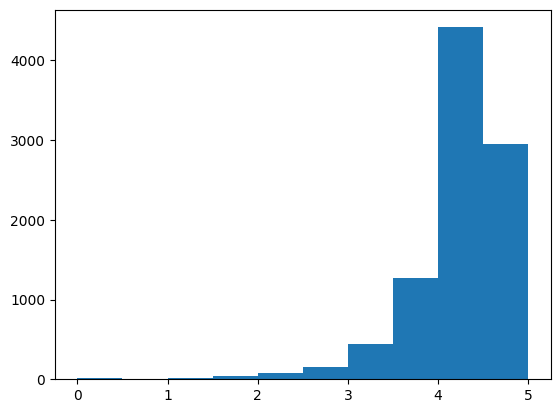

In [473]:
plt.hist(df_apps_clean['Rating'])

#Before choosing an imputation method, the following aspects were considered:
`Missing Value Percentage`: The missing values represent a noticeable but manageable proportion of the dataset.

`Data Distribution`: The Rating variable is concentrated around higher values and is not perfectly normally distributed.

`Median Robustness`: The median is less sensitive to extreme values than the mean.

`Rating Range`: Ratings are numerical values ranging from 1 to 5, so the imputed value must remain within this range.

In [474]:
df_apps_clean['Rating']=df_apps_clean['Rating'].fillna(df_apps_clean['Rating'].median())

In [475]:
df_apps_clean.isna().sum()

,0
App,0
Category,0
Rating,0
Reviews,0
Size_MBs,0
Installs,0
Type,1
Price,0
Content_Rating,0
Genres,0


In [476]:
df_apps_clean['Type'] = df_apps_clean['Type'].fillna('Free')
df_apps_clean.sample(5)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres
10141,"Video Editor Music,Cut,No Crop",PHOTOGRAPHY,4.7,2163282,6.900000,50000000,Free,0,Everyone,Photography
8494,The Maner,PRODUCTIVITY,4.2,53015,2.200000,5000000,Free,0,Everyone,Productivity
986,EY Tax Briefing,BUSINESS,4.3,3,15.000000,100,Free,0,Everyone,Business
5876,Next Portuguese(BR) Langpack,TOOLS,4.3,1320,0.759766,100000,Free,0,Everyone,Tools
338,MinT BI,PRODUCTIVITY,4.3,0,2.900000,10,Free,0,Everyone,Productivity


In [477]:
#verification la derniere fois
df_apps_clean.isna().sum()

,0
App,0
Category,0
Rating,0
Reviews,0
Size_MBs,0
Installs,0
Type,0
Price,0
Content_Rating,0
Genres,0


In [498]:
df_apps_clean['App'] = df_apps_clean['App'].astype(str).str.strip().str.lower()
df_apps_clean = df_apps_clean.sort_values(by='Reviews', ascending=False)
df_apps_clean = df_apps_clean.drop_duplicates(subset=['App'], keep='first')
df_apps_clean = df_apps_clean.reset_index(drop=True)

In [499]:
print(df_apps_clean['App'].value_counts().sample(5))

App
exiled kingdoms rpg                                1
pixelmania - color by number & create pixel art    1
nema ei                                            1
instant ba-dum-tss                                 1
co-op credit union on the go                       1
Name: count, dtype: int64


### Handling Duplicates Strategy

**The Challenge:**
Standard `drop_duplicates()` failed to remove some apps (e.g., WhatsApp) because of slight name variations (spaces, uppercase) or because they appeared as multiple versions with different review counts.

**The Solution:**
1. **Normalization:** Converted app names to lowercase and removed extra spaces (`str.strip().str.lower()`).
2. **Smart Filtering:** Sorted the data by `Reviews` (highest first), then applied `drop_duplicates(subset=['App'], keep='first')`.

**Why?**
This ensures we keep the most popular version of each app and guarantees accurate results for our "Most Installed" analysis.

## Step 4 —Analysis – Top 10 Highest-Rated Applications

In [480]:
# Force la colonne Rating à devenir purement numérique
df_apps_clean["Rating"] = pd.to_numeric(
    df_apps_clean["Rating"], errors="coerce"
)
top_rated = df_apps_clean.sort_values(by="Rating", ascending=False)
top_rated[["App", "Rating", "Reviews"]].head(10)


,App,Rating,Reviews
8324,EF Academy,5.0,4
8302,FH School,5.0,4
8679,Cy-Fair VFD EMS Protocols,5.0,2
8210,Jigsaw Volvo FH 16 Trucks,5.0,5
8205,Shabad Gurubani Punjabi mp3 free - Ek Onkar Sa...,5.0,5
8199,The CJ Rubric,5.0,5
8452,Sway Medical,5.0,3
8450,BV,5.0,3
7793,South Florida AA Meetings,5.0,10
8463,BV Mobile Apps,5.0,3


The analysis identifies the ten applications with the highest ratings in the dataset.

All applications in the selected top 10 have a rating of 5.0. However, their number of reviews is relatively low, ranging from only a few reviews to a few dozen.

**Conclusion:**

A perfect rating does not necessarily indicate high popularity or strong user engagement. Therefore, ratings should be interpreted alongside the number of reviews to obtain a more reliable understanding of application performance.

## Step 5 —Analysis – Five Largest Applications



In [481]:
# Afficher les 5 tailles les plus grandes
largest_apps = df_apps_clean.nlargest(5, 'Size_MBs')
largest_apps[["App", "Size_MBs"]]



,App,Size_MBs
62,Hungry Shark Evolution,100.0
103,SimCity BuildIt,100.0
556,Mini Golf King - Multiplayer Game,100.0
891,Miami crime simulator,100.0
1073,Ultimate Tennis,100.0


This analysis identifies the five applications with the largest file sizes.

The results show that all five applications have a size of 100 MB, which is the maximum size observed in the dataset.

**Conclusion:**

Application size can vary significantly depending on its features and content. However, a larger application size does not automatically mean better quality or higher popularity.

## Step 6 — Most Reviewed Applications

In [482]:
# apps a plus de reviews
largest_apps = df_apps_clean.nlargest(50, 'Reviews')
largest_apps[["App", "Reviews",'Type']]




,App,Reviews,Type
0,Facebook,78158306,Free
1,WhatsApp Messenger,69119316,Free
2,Instagram,66577446,Free
3,Messenger – Text and Video Chat for Free,56646578,Free
4,Clash of Clans,44893888,Free
5,Clean Master- Space Cleaner & Antivirus,42916526,Free
6,Subway Surfers,27725352,Free
7,YouTube,25655305,Free
8,"Security Master - Antivirus, VPN, AppLock, Boo...",24900999,Free
9,Clash Royale,23136735,Free


In [483]:
(largest_apps['Type']=='Paid').sum()

np.int64(0)

This analysis identifies the applications with the highest number of user reviews.

The results show that well-known applications such as Facebook, WhatsApp Messenger, Instagram, and Messenger occupy the leading positions.

These applications receive millions of reviews, indicating a high level of user interaction and engagement.

**Conclusion:**

Communication and social media applications dominate the list of most-reviewed applications. This suggests that applications used frequently for daily communication tend to generate significant user engagement.

## Step 7 — Analysis – Application Distribution by Content Rating

In [484]:
# visualisation de repartition
content_counts = df_apps_clean["Content_Rating"].value_counts()
fig_pie = px.pie(
 names=content_counts.index,
 values=content_counts.values,
 title="Répartition des applications selon Content Rating"
)
fig_pie.show()




The pie chart illustrates how applications are distributed according to their content rating.

The results show that the "Everyone" category represents the largest share of applications, accounting for approximately 81.8% of the dataset. The "Teen" category represents a smaller proportion, while the remaining categories account for relatively limited shares.

**Conclusion:**

Most applications in the dataset are designed for a general audience. This indicates that developers tend to target applications toward users of different age groups rather than focusing exclusively on restricted audiences.

In [485]:
fig_donut = px.pie(names=content_counts.index,
 values=content_counts.values,
 title="Content Rating — Donut chart",
 hole=0.45
)
fig_donut.show()

The donut chart provides another visual representation of the distribution of applications by content rating.

It highlights the dominance of the "Everyone" category and makes the proportions of the different audience classifications easier to compare.

**Conclusion:**

The donut chart confirms the observations from the previous pie chart. Both visualizations communicate the same distribution, but the donut format offers a cleaner alternative for presenting proportions.

In [486]:
df_apps_clean['Installs'].dtypes

dtype('int64')

In [487]:
df_apps_clean['Installs'].value_counts()

,count
Installs,
1000000,1417
100000,1113
10000,1030
10000000,937
1000,888
100,709
5000000,607
500000,504
50000,469


In [488]:
print(df_apps_clean["Installs"].dtype)

int64


## Step 8 — Analysis – Most Installed Applications

In [489]:
df_apps_clean.nlargest(10,'Installs')

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres
0,Facebook,SOCIAL,4.1,78158306,5.30,1000000000,Free,0,Teen,Social
1,WhatsApp Messenger,COMMUNICATION,4.4,69119316,3.50,1000000000,Free,0,Everyone,Communication
2,Instagram,SOCIAL,4.5,66577446,5.30,1000000000,Free,0,Teen,Social
3,Messenger – Text and Video Chat for Free,COMMUNICATION,4.0,56646578,3.50,1000000000,Free,0,Everyone,Communication
6,Subway Surfers,GAME,4.5,27725352,76.00,1000000000,Free,0,Everyone 10+,Arcade
7,YouTube,VIDEO_PLAYERS,4.3,25655305,4.65,1000000000,Free,0,Teen,Video Players & Editors
22,Google Photos,PHOTOGRAPHY,4.5,10859051,6.90,1000000000,Free,0,Everyone,Photography
25,Skype - free IM & video calls,COMMUNICATION,4.1,10484169,3.50,1000000000,Free,0,Everyone,Communication
33,Google Chrome: Fast & Secure,COMMUNICATION,4.3,9643041,3.50,1000000000,Free,0,Everyone,Communication
34,Maps - Navigate & Explore,TRAVEL_AND_LOCAL,4.3,9235373,12.00,1000000000,Free,0,Everyone,Travel & Local


This analysis identifies the applications with the highest number of installations.

The results show that major applications such as Google Play Books, Messenger, WhatsApp, Google Chrome, Gmail, Hangouts, and Skype appear among the most installed applications, with some reaching one billion installations.

**Conclusion:**

Popular communication and Google services occupy leading positions in terms of installations. This highlights the importance of accessibility, everyday usefulness, and strong brand recognition in application adoption.

In [490]:
# Nettoyer le symbole dollar et convertir en nombre
df_apps_clean["Price"] = (
    df_apps_clean["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
)
df_apps_clean["Price"] = pd.to_numeric(
    df_apps_clean["Price"], errors="coerce"
)

## Step 9 — Analysis – Most Expensive Applications

In [491]:
# Les 20 applications les plus chères
most_expensive = df_apps_clean.nlargest(20, "Price")
most_expensive[["App", "Price", "Type"]]

,App,Price,Type
5648,I'm Rich - Trump Edition,400.00,Paid
3986,I am rich,399.99,Paid
4441,I Am Rich Premium,399.99,Paid
4913,I am Rich Plus,399.99,Paid
5031,💎 I'm rich,399.99,Paid
5312,I am rich(premium),399.99,Paid
5859,I Am Rich Pro,399.99,Paid
5938,I am Rich,399.99,Paid
6156,I am rich (Most expensive app),399.99,Paid
6373,I am Rich!,399.99,Paid



This analysis identifies the twenty most expensive applications in the dataset.

The results show that several applications have unusually high prices, with some reaching approximately $400.

A significant number of these applications belong to the "I am Rich" category of premium applications.

**Conclusion:**

A high application price does not necessarily indicate greater functionality or popularity. The results highlight the presence of niche premium applications with unusually high prices.

## Step 10 — Analysis – Top 10 Paid Applications by Estimated Revenue

In [492]:
# new colones
df_apps_clean["Revenue_Estimate"] = (
    df_apps_clean["Price"] * df_apps_clean["Installs"])

df_apps_clean.sample(5)

,App,Category,Rating,Reviews,Size_MBs,Installs,Type,Price,Content_Rating,Genres,Revenue_Estimate
5494,"Real Casino:Slot,Keno,BJ,Poker",GAME,4.1,341,26.0,50000,Free,0.0,Teen,Casino,0.0
672,Opera Mini browser beta,COMMUNICATION,4.4,401530,3.5,10000000,Free,0.0,Everyone,Communication,0.0
855,Race the Traffic Moto,GAME,3.8,270687,38.0,10000000,Free,0.0,Teen,Racing,0.0
820,Masha and the Bear Child Games,FAMILY,4.1,288606,92.0,10000000,Free,0.0,Everyone,Adventure;Education,0.0
3300,Henry Danger Crime Warp,FAMILY,4.6,9626,28.0,1000000,Free,0.0,Everyone,Action;Action & Adventure,0.0


In [493]:
# Ne garder que les applications payantes
paid_apps = df_apps_clean[df_apps_clean["Type"] == "Paid"].copy()
# Trier selon le revenu estimé
top_10_paid = paid_apps.nlargest(10, "Revenue_Estimate")
print(top_10_paid[
    ["App", "Category", "Price", "Installs", "Revenue_Estimate"]
])

# Compter les jeux parmi les dix premières
nb_games = (top_10_paid["Category"] == "GAME").sum()
print("Nombre de jeux dans le top 10 :", nb_games)

                                App     Category   Price  Installs  \
172                       Minecraft       FAMILY    6.99  10000000   
3986                      I am rich    LIFESTYLE  399.99    100000   
4441              I Am Rich Premium      FINANCE  399.99     50000   
660                   Hitman Sniper         GAME    0.99  10000000   
730   Grand Theft Auto: San Andreas         GAME    6.99   1000000   
1954            Facetune - For Free  PHOTOGRAPHY    5.99   1000000   
2593        Sleep as Android Unlock    LIFESTYLE    5.99   1000000   
1531            DraStic DS Emulator         GAME    4.99   1000000   
5648       I'm Rich - Trump Edition    LIFESTYLE  400.00     10000   
4913                 I am Rich Plus       FAMILY  399.99     10000   

      Revenue_Estimate  
172         69900000.0  
3986        39999000.0  
4441        19999500.0  
660          9900000.0  
730          6990000.0  
1954         5990000.0  
2593         5990000.0  
1531         4990000.0  
5648

This analysis focuses on paid applications and estimates their potential gross revenue using the following formula:

Estimated Revenue = Price × Number of Installs

The results show that Minecraft ranks first, followed by several premium applications and popular paid games.

Three applications in the top ten belong to the GAME category.

**Conclusion:**

The results suggest that both application price and installation volume influence estimated revenue. Popular paid applications can generate high estimated revenue even when their prices are relatively low.

## Step 11 — Analysis – Distribution of Applications by Category
This histogram illustrates the distribution of Android applications across different categories, with categories arranged in descending order according to the number of applications.

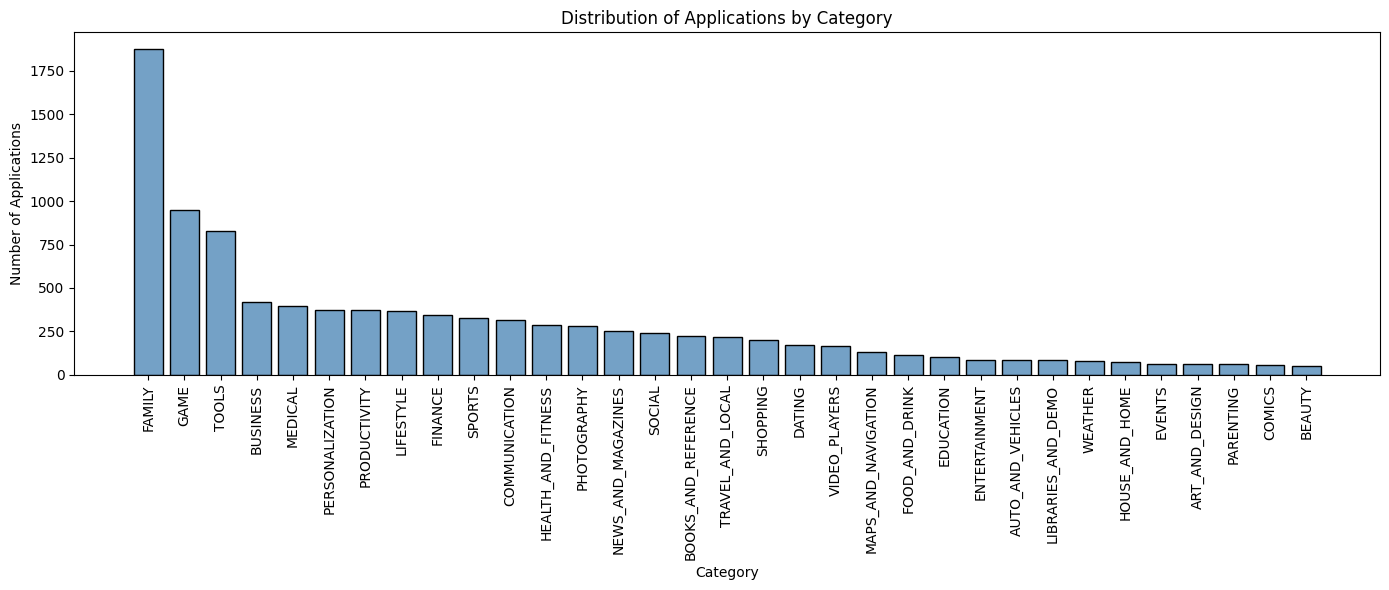

In [494]:
# Count applications by category (descending order)
category_counts = df_apps_clean["Category"].value_counts()
# Define categories in descending order
ordered_categories = category_counts.index.tolist()
# Convert Category into an ordered categorical variable
df_apps_clean["Category"] = pd.Categorical(
    df_apps_clean["Category"],
    categories=ordered_categories,
    ordered=True
)
# Plot histogram
plt.figure(figsize=(14, 6))
sns.histplot(
    data=df_apps_clean,
    x="Category",
    discrete=True,
    shrink=0.8,
    color="steelblue"
)
plt.xticks(rotation=90)
plt.title("Distribution of Applications by Category")
plt.xlabel("Category")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()



** Key Observations:**
* **High Competition:** The market is heavily saturated in entertainment and utility apps. **"FAMILY"** dominates with over 1,800 apps, followed by **"GAME"** and **"TOOLS"**.
* **The Long Tail:** There is a steep drop-off after the top 3 categories. Most other categories (e.g., Finance, Shopping, Education) have fewer than 400 applications, creating a long, flat tail on the right side of the chart.

** Takeaway:**
Developing an app in "Family" or "Game" requires a massive marketing budget to stand out. Categories on the right (like *Parenting* or *Events*) offer less competition (niche markets), though they likely have a smaller user base.

## step 12 Analysis – Total Installations by Category


/tmp/ipykernel_3472/3237905581.py:2: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



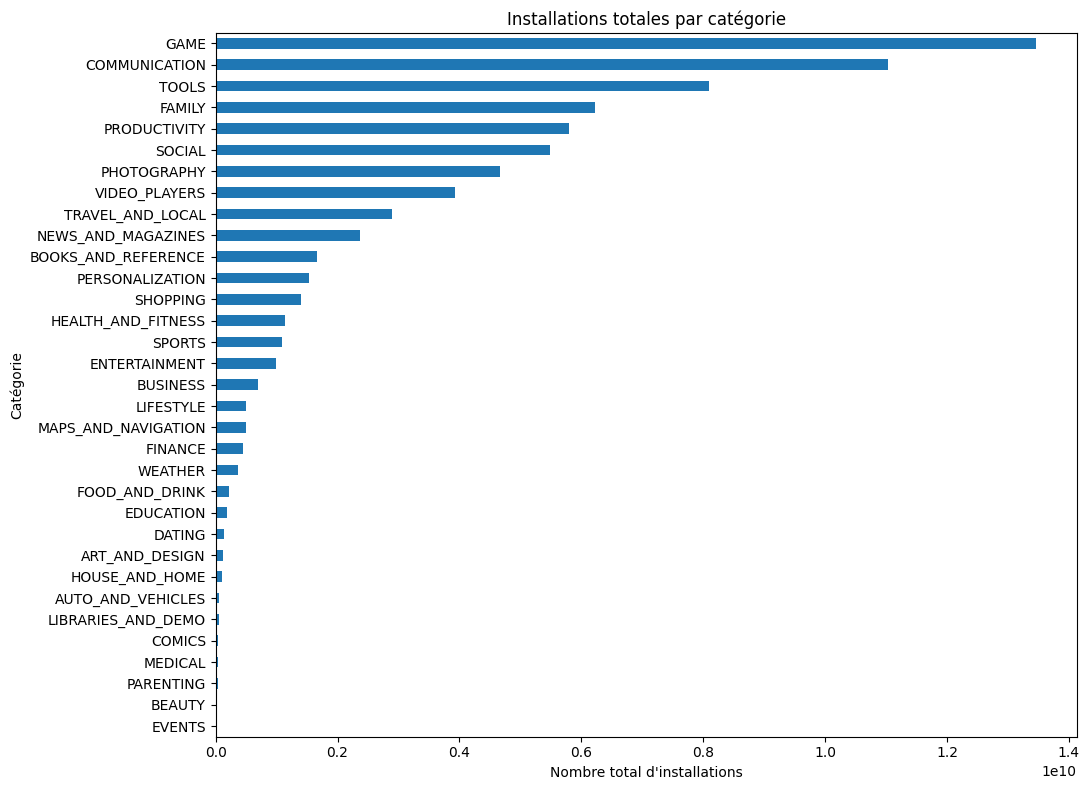

In [495]:
installs_by_category = (
    df_apps_clean.groupby("Category")["Installs"]
    .sum()
    .sort_values(ascending=True)
)
plt.figure(figsize=(11, 8))
installs_by_category.plot(kind="barh")
plt.title("Installations totales par catégorie")
plt.xlabel("Nombre total d'installations")
plt.ylabel("Catégorie")
plt.tight_layout()
plt.show()

* **Key Observations:**
* **Top Performers:** **"GAME"** is the undisputed leader in total downloads, followed closely by **"COMMUNICATION"** and **"TOOLS"**.
* **High Engagement:** Categories like *Productivity*, *Social*, and *Photography* also show massive download volumes.
* **Data Skew:** The fact that "GAME" has the highest installs but was 2nd in app count (Q12) means the average game gets far more downloads than apps in other categories.

**Takeaway:**
Games and Communication apps are the primary drivers of user acquisition on the Play Store. The sheer volume of installs in these top categories makes them highly attractive for monetization (ads/in-app purchases), despite the fierce competition.

In [496]:
category_summary = (
    df_apps_clean.groupby("Category")
    .agg(
        Number_of_Apps=("App", "nunique"),
        Total_Installs=("Installs", "sum")
    )
    .reset_index()
)
category_summary.head()

/tmp/ipykernel_3472/189426028.py:2: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



,Category,Number_of_Apps,Total_Installs
0,FAMILY,1877,6227542505
1,GAME,946,13457924415
2,TOOLS,829,8102771915
3,BUSINESS,420,697164865
4,MEDICAL,395,38293077


## Step 13 — Downloads vs. Competition (Scatter Plot)

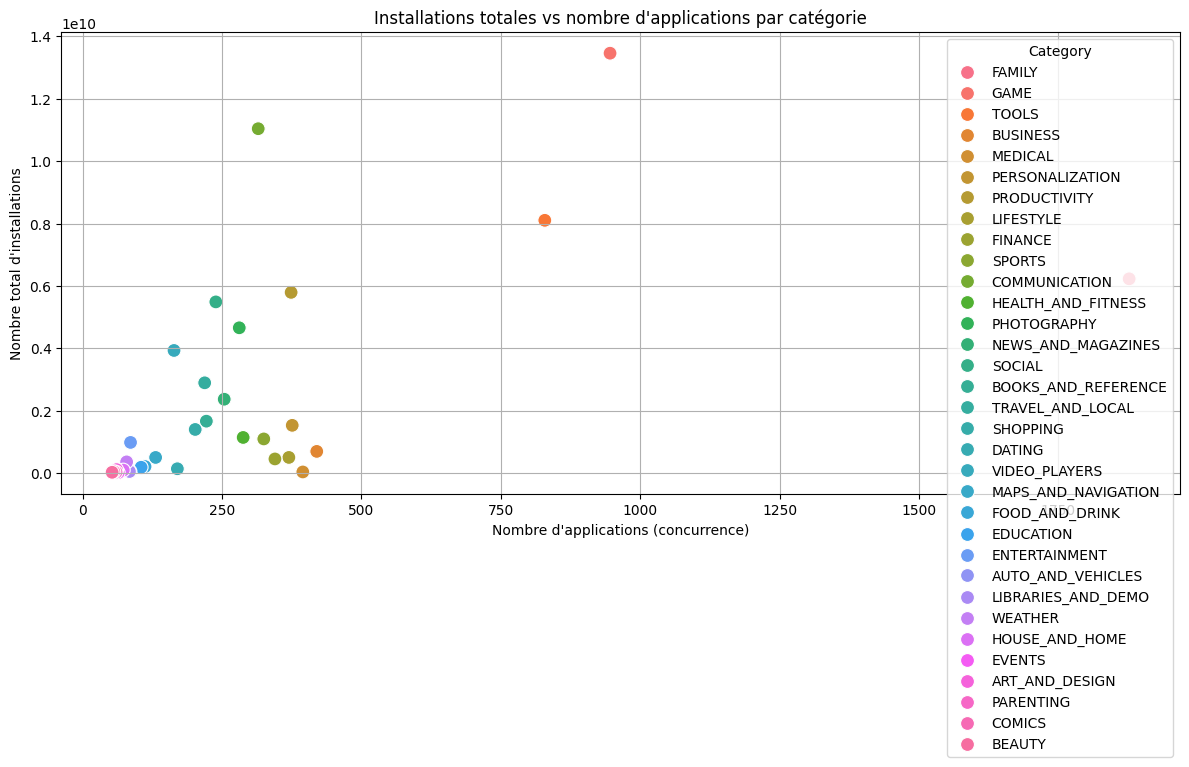

In [497]:
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=category_summary,
    x="Number_of_Apps",
    y="Total_Installs",
    hue="Category",
    s=100
)
plt.title("Installations totales vs nombre d'applications par catégorie")
plt.xlabel("Nombre d'applications (concurrence)")
plt.ylabel("Nombre total d'installations")
plt.grid()
plt.tight_layout()
plt.show()

**Key Insights:**
* **High-Risk/High-Reward:** Categories like **GAME** and **COMMUNICATION** (top-right) have massive downloads but extreme competition (too many apps).
* **The "Sweet Spot":** Categories like **BUSINESS** and **TOOLS** (top-left) show high downloads with relatively low competition.

**Best Categories to Target:**
The most profitable categories to develop for are those with **high demand but low competition** (the top-left area). Developers should target **Business**, **Productivity**, or **Tools** to easily rank higher and generate revenue. Niche categories (bottom-left) are also good for low-budget startups, whereas GAME is only viable for large budgets.

# General Conclusion: Android Apps Market Analysis

This comprehensive analysis of the Google Play Store dataset (comprising thousands of applications) provides valuable insights into the mobile app ecosystem, user behavior, and market dynamics.

###  Key Findings
1. **Market Saturation vs. User Demand:**
   While categories like **FAMILY** and **GAME** have the highest number of applications (intense competition), **GAME** and **COMMUNICATION** dominate in terms of total downloads. This indicates that users spend the majority of their time on entertainment and social connectivity.
2. **The Importance of Reviews over Ratings:**
   Relying solely on app ratings is misleading. Many applications have a perfect 5.0 rating but only a handful of reviews. High ratings must be correlated with high review counts to accurately reflect true app quality.
3. **Revenue Generation (Monetization):**
   The mobile market is overwhelmingly driven by the "Free" model. High-revenue apps usually rely on in-app purchases or ads rather than upfront pricing. However, a niche market exists for premium (Paid) apps, with 3 games making it into the Top 10 highest estimated revenue apps (e.g., *Minecraft*).
4. **Data Quality Challenges:**
   Real-world data is messy. Successfully extracting actionable insights required extensive data cleaning—handling missing values (NaN), removing duplicates, and converting string variables (like `Installs` with commas and `Price` with dollar signs) into usable numeric formats.

###  Strategic Recommendations for Developers
If the goal is to launch a new application and maximize profitability, developers should consider two main strategies:
* **The High-Risk/High-Reward Strategy:** Enter highly competitive categories (like *Games* or *Tools*) but ensure a massive marketing budget to stand out.
* **The Niche Strategy:** Target categories located in the "long tail" of the distribution (e.g., *Parenting, Events, or specific Medical tools*). These categories have significantly less competition, making it easier to rank higher in search results and capture a dedicated audience.

**Final Thought:**
The Google Play Store is a mature and highly competitive market. Success no longer comes from just building an app, but from understanding user acquisition dynamics, optimizing for ratings/reviews, and choosing the right monetization strategy based on the specific category's behavior.